In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)
print("Loaded file:", filename)
print("Shape:", df.shape)
df.head()

Saving 1651277648862_healthinsurance.csv to 1651277648862_healthinsurance (1).csv
Loaded file: 1651277648862_healthinsurance (1).csv
Shape: (15000, 13)


,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title,claim
0,60.0,male,64,24.3,NoDisease,1,0,NewYork,72,0,0,Actor,13112.6
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78,1,1,Engineer,9567.0
2,32.0,female,64,17.8,Epilepsy,2,1,Phildelphia,88,1,1,Academician,32734.2
3,61.0,female,53,36.4,NoDisease,1,1,Pittsburg,72,1,0,Chef,48517.6
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82,1,0,HomeMakers,1731.7


In [2]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df.describe()

Missing values per column:
age                    396
sex                      0
weight                   0
bmi                    956
hereditary_diseases      0
no_of_dependents         0
smoker                   0
city                     0
bloodpressure            0
diabetes                 0
regular_ex               0
job_title                0
claim                    0
dtype: int64

Duplicate rows: 1096


,age,weight,bmi,no_of_dependents,smoker,bloodpressure,diabetes,regular_ex,claim
count,14604.000000,15000.000000,14044.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,39.547521,64.909600,30.266413,1.129733,0.198133,68.650133,0.777000,0.224133,13401.437620
std,14.015966,13.701935,6.122950,1.228469,0.398606,19.418515,0.416272,0.417024,12148.239619
min,18.000000,34.000000,16.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1121.900000
25%,27.000000,54.000000,25.700000,0.000000,0.000000,64.000000,1.000000,0.000000,4846.900000
50%,40.000000,63.000000,29.400000,1.000000,0.000000,71.000000,1.000000,0.000000,9545.650000
75%,52.000000,76.000000,34.400000,2.000000,0.000000,80.000000,1.000000,0.000000,16519.125000
max,64.000000,95.000000,53.100000,5.000000,1.000000,122.000000,1.000000,1.000000,63770.400000


In [3]:
df = df.drop_duplicates().reset_index(drop=True)

print("Rows with 0 bloodpressure:", (df["bloodpressure"] == 0).sum())
df.loc[df["bloodpressure"] <= 0, "bloodpressure"] = np.nan

if df["smoker"].dtype == object:
    df["smoker"] = df["smoker"].str.lower().isin(["yes", "1", "true"]).astype(int)

print("Cleaned dataset shape:", df.shape)

Rows with 0 bloodpressure: 703
Cleaned dataset shape: (13904, 13)


Raw claim skewness: 1.489
Log-transformed claim skewness: -0.083


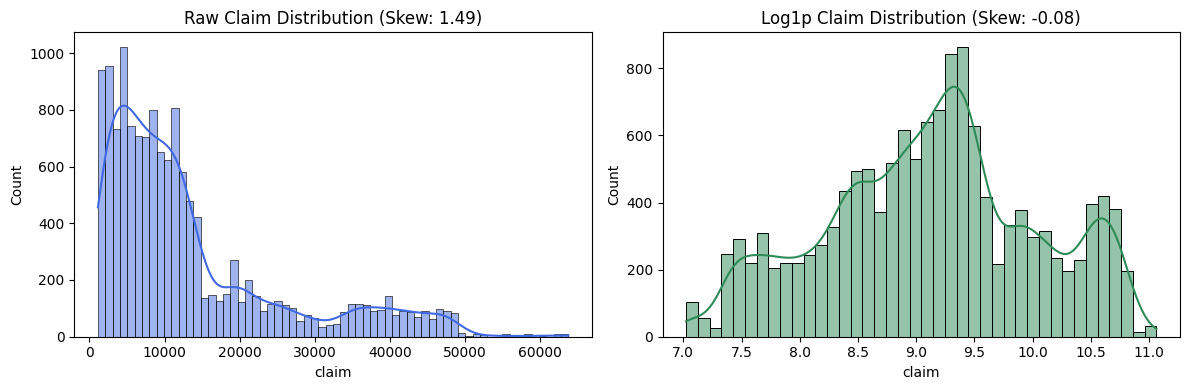

In [4]:
raw_skew = df["claim"].skew()
log_skew = np.log1p(df["claim"]).skew()

print(f"Raw claim skewness: {raw_skew:.3f}")
print(f"Log-transformed claim skewness: {log_skew:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["claim"], kde=True, ax=ax[0], color="royalblue")
ax[0].set_title(f"Raw Claim Distribution (Skew: {raw_skew:.2f})")

sns.histplot(np.log1p(df["claim"]), kde=True, ax=ax[1], color="seagreen")
ax[1].set_title(f"Log1p Claim Distribution (Skew: {log_skew:.2f})")
plt.tight_layout()
plt.show()

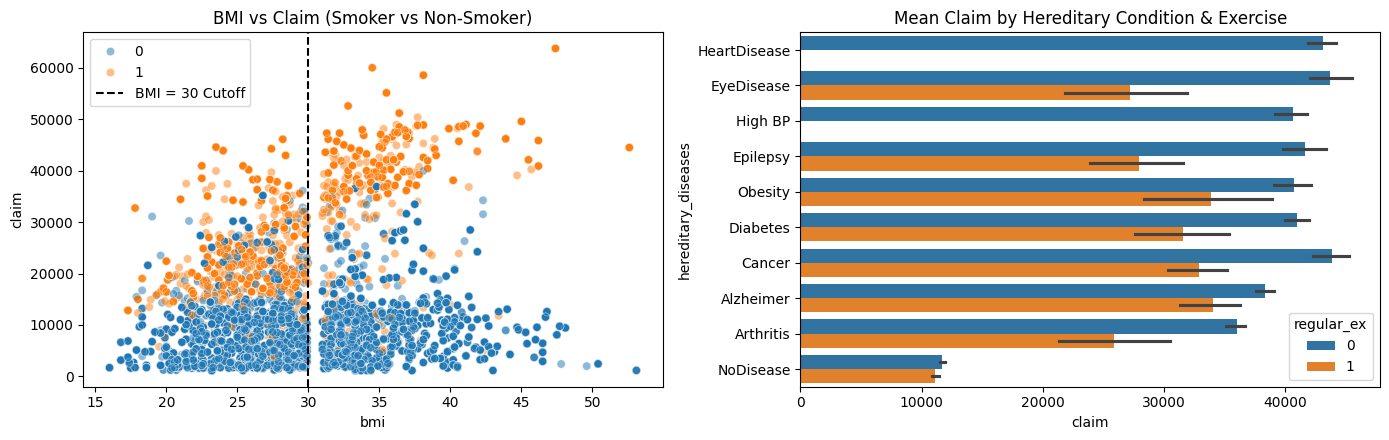

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

sns.scatterplot(data=df, x="bmi", y="claim", hue="smoker", alpha=0.5, ax=ax[0])
ax[0].axvline(30, color="black", linestyle="--", label="BMI = 30 Cutoff")
ax[0].set_title("BMI vs Claim (Smoker vs Non-Smoker)")
ax[0].legend()

order = df.groupby("hereditary_diseases")["claim"].mean().sort_values(ascending=False).index
sns.barplot(
    data=df, x="claim", y="hereditary_diseases",
    order=order, hue="regular_ex", ax=ax[1]
)
ax[1].set_title("Mean Claim by Hereditary Condition & Exercise")

plt.tight_layout()
plt.savefig("eda_plots.png", dpi=150)
plt.show()

In [6]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

cols_6 = ["age", "sex", "bmi", "no_of_dependents", "smoker", "city"]

cols_12 = [
    "age", "sex", "weight", "bmi", "hereditary_diseases",
    "no_of_dependents", "smoker", "city", "bloodpressure",
    "diabetes", "regular_ex", "job_title"
]

def get_preprocessor(use_clinical=True):
    if not use_clinical:
        num_cols = ["age", "bmi", "no_of_dependents", "smoker"]
        cat_cols = ["sex", "city"]
    else:
        num_cols = [
            "age", "weight", "bmi", "no_of_dependents",
            "smoker", "bloodpressure", "diabetes", "regular_ex"
        ]
        cat_cols = ["sex", "hereditary_diseases", "city", "job_title"]

    num_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", num_transformer, num_cols),
        ("cat", cat_transformer, cat_cols)
    ])

In [7]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression (Log Target)": TransformedTargetRegressor(
        regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1
    ),
    "Ridge Regression": Ridge(alpha=1.0),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=12, min_samples_leaf=3, n_jobs=-1, random_state=42
    )
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

y = df["claim"]
results = []

for label, cols, is_clin in [
    ("6-Feature Baseline", cols_6, False),
    ("12-Feature Clinical", cols_12, True)
]:
    X_sub = df[cols]
    for name, reg in models.items():
        pipe = Pipeline([
            ("prep", get_preprocessor(is_clin)),
            ("model", reg)
        ])
        scores = cross_validate(pipe, X_sub, y, cv=cv, scoring=scoring, n_jobs=-1)
        results.append({
            "Feature Set": label,
            "Model": name,
            "CV MAE": round(-scores["test_MAE"].mean(), 2),
            "CV RMSE": round(-scores["test_RMSE"].mean(), 2),
            "CV R2": round(scores["test_R2"].mean(), 4)
        })

results_df = pd.DataFrame(results).sort_values(by=["Feature Set", "CV RMSE"])
results_df

,Feature Set,Model,CV MAE,CV RMSE,CV R2
7,12-Feature Clinical,Random Forest,1088.19,2626.15,0.9528
6,12-Feature Clinical,Gradient Boosting,2323.61,3961.87,0.8932
5,12-Feature Clinical,Ridge Regression,3876.96,5946.18,0.7597
4,12-Feature Clinical,Linear Regression (Log Target),4245.88,8228.14,0.5388
3,6-Feature Baseline,Random Forest,1555.51,3510.35,0.9160
2,6-Feature Baseline,Gradient Boosting,3000.37,5100.10,0.8231
1,6-Feature Baseline,Ridge Regression,4438.96,6566.43,0.7068
0,6-Feature Baseline,Linear Regression (Log Target),4403.39,8357.42,0.5253


In [8]:
best_6_model = Pipeline([
    ("prep", get_preprocessor(False)),
    ("model", RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=3, n_jobs=-1, random_state=42))
]).fit(df[cols_6], y)

best_12_model = Pipeline([
    ("prep", get_preprocessor(True)),
    ("model", RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=3, n_jobs=-1, random_state=42))
]).fit(df[cols_12], y)

sample = df.iloc[[0]]
print("Actual Claim:    ", sample["claim"].values[0])
print("6-Feature Pred:  ", round(best_6_model.predict(sample[cols_6])[0], 2))
print("12-Feature Pred: ", round(best_12_model.predict(sample[cols_12])[0], 2))


Actual Claim:     13112.6
6-Feature Pred:   13103.2
12-Feature Pred:  13836.73


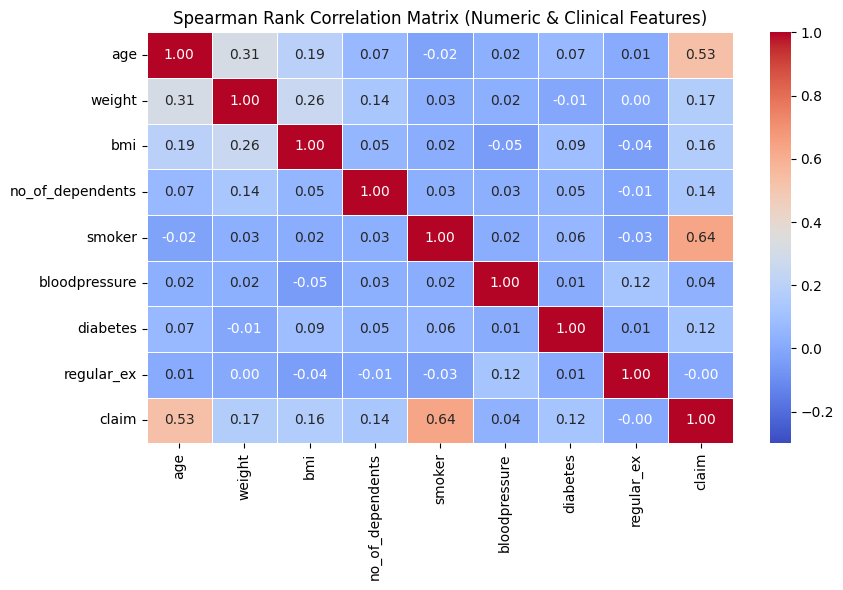

In [9]:
# Compare numeric features using Spearman correlation (captures non-linear monotonic relationships)
num_features = ["age", "weight", "bmi", "no_of_dependents", "smoker", "bloodpressure", "diabetes", "regular_ex", "claim"]
spearman_corr = df[num_features].corr(method="spearman")

plt.figure(figsize=(9, 6))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.3, vmax=1.0, linewidths=0.5)
plt.title("Spearman Rank Correlation Matrix (Numeric & Clinical Features)")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

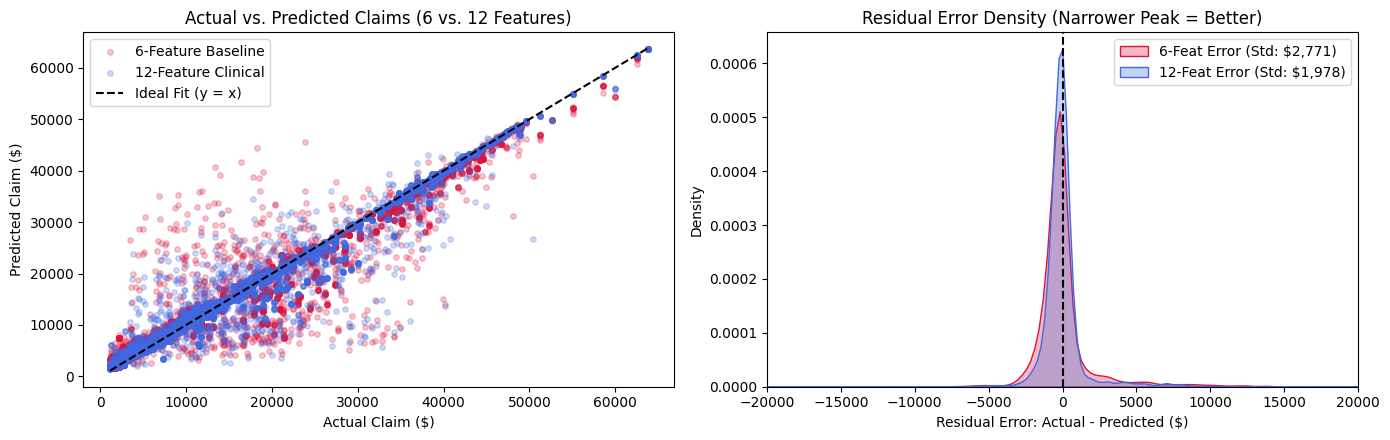

In [10]:
pred_6_all = best_6_model.predict(df[cols_6])
pred_12_all = best_12_model.predict(df[cols_12])

residuals_6 = y - pred_6_all
residuals_12 = y - pred_12_all

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].scatter(y, pred_6_all, alpha=0.25, color="crimson", label="6-Feature Baseline", s=15)
ax[0].scatter(y, pred_12_all, alpha=0.25, color="royalblue", label="12-Feature Clinical", s=15)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", lw=1.5, label="Ideal Fit (y = x)")
ax[0].set_xlabel("Actual Claim ($)")
ax[0].set_ylabel("Predicted Claim ($)")
ax[0].set_title("Actual vs. Predicted Claims (6 vs. 12 Features)")
ax[0].legend()

sns.kdeplot(residuals_6, fill=True, color="crimson", alpha=0.3, label=f"6-Feat Error (Std: ${residuals_6.std():,.0f})", ax=ax[1])
sns.kdeplot(residuals_12, fill=True, color="royalblue", alpha=0.3, label=f"12-Feat Error (Std: ${residuals_12.std():,.0f})", ax=ax[1])
ax[1].axvline(0, color="black", linestyle="--")
ax[1].set_xlim(-20000, 20000)
ax[1].set_xlabel("Residual Error: Actual - Predicted ($)")
ax[1].set_title("Residual Error Density (Narrower Peak = Better)")
ax[1].legend()

plt.tight_layout()
plt.savefig("residual_analysis.png", dpi=150)
plt.show()

/tmp/ipykernel_3405/4084736647.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df, x="Importance", y="Feature", palette="viridis")


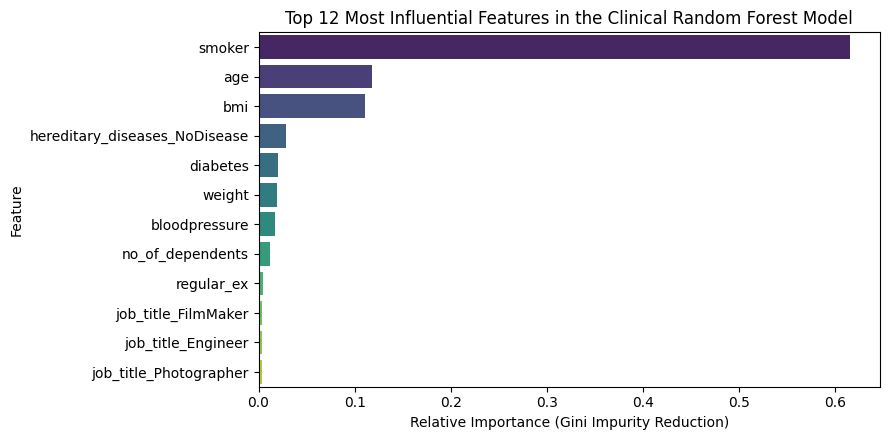

In [11]:
feature_names = best_12_model.named_steps["prep"].get_feature_names_out()
importances = best_12_model.named_steps["model"].feature_importances_

clean_names = [name.replace("num__", "").replace("cat__", "") for name in feature_names]

feat_imp_df = pd.DataFrame({
    "Feature": clean_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).head(12)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=feat_imp_df, x="Importance", y="Feature", palette="viridis")
plt.title("Top 12 Most Influential Features in the Clinical Random Forest Model")
plt.xlabel("Relative Importance (Gini Impurity Reduction)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

In [12]:
import joblib

bundle = {
    "model_6": best_6_model,
    "model_12": best_12_model,
    "cv_results": results_df,
    "cities": sorted(df["city"].dropna().unique().tolist()),
    "diseases": sorted(df["hereditary_diseases"].dropna().unique().tolist()),
    "jobs": sorted(df["job_title"].dropna().unique().tolist())
}

joblib.dump(bundle, "model_bundle.joblib", compress=3)
print("Saved model_bundle.joblib successfully!")

Saved model_bundle.joblib successfully!
